In [3]:
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import pandas as pd
import umap
import kagglehub
import os
from tools import generate_plot

dataset_path = kagglehub.dataset_download("zalando-research/fashionmnist")
print(f"Dane pobrane do: {dataset_path}")

train_path = os.path.join(dataset_path, "fashion-mnist_train.csv")
test_path = os.path.join(dataset_path, "fashion-mnist_test.csv")

df_train = pd.read_csv(train_path)
df_test = pd.read_csv(test_path)

df = pd.concat([df_train, df_test], ignore_index=True)
print(f"Pełny połączony dataset ma kształt: {df.shape}")

clothes_dict = {
    0: 'T-shirt/top',
    1: 'Trouser',
    2: 'Pullover',
    3: 'Dress',
    4: 'Coat',
    5: 'Sandal',
    6: 'Shirt',
    7: 'Sneaker',
    8: 'Bag',
    9: 'Ankle boot'
}

labels = df['label']
df_pixel_only = df.drop('label',axis=1)
mapped_labels = labels.map(clothes_dict)

Dane pobrane do: C:\Users\jacek\.cache\kagglehub\datasets\zalando-research\fashionmnist\versions\4
Pełny połączony dataset ma kształt: (70000, 785)


Wizualizacja danych na kilka sposobów:

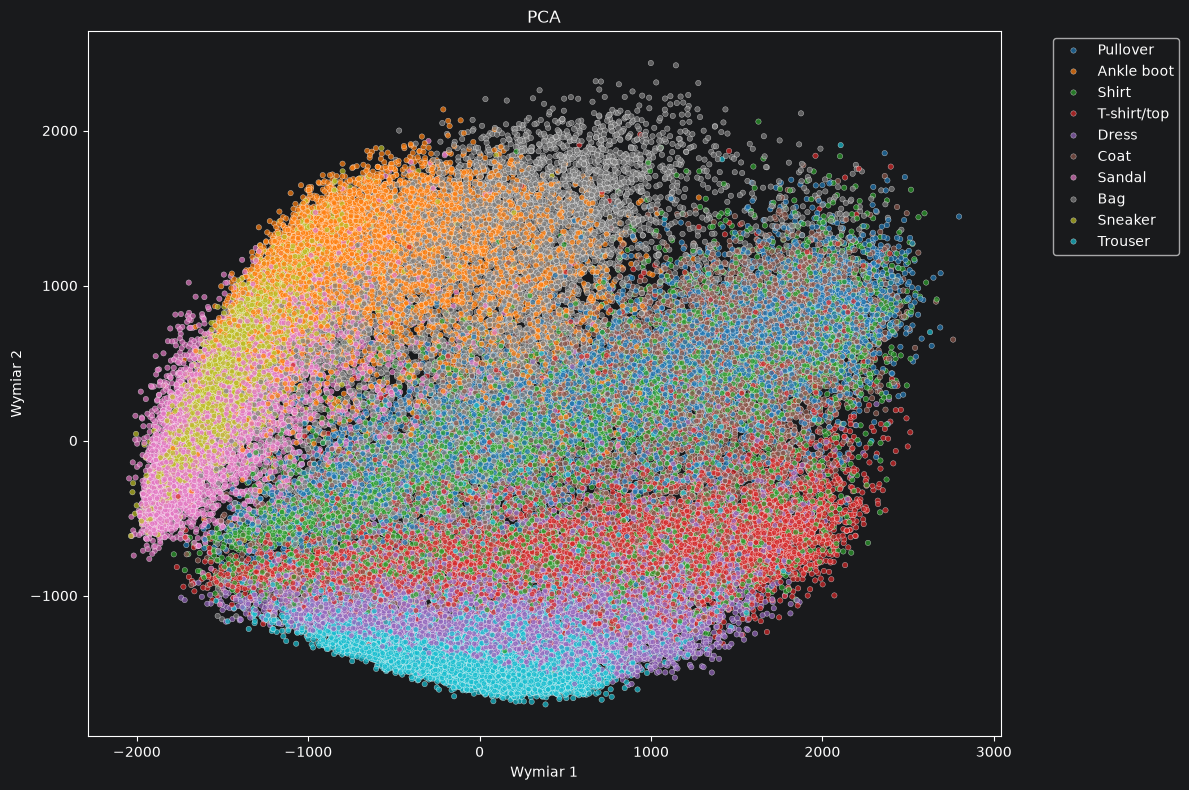

In [4]:
pca = PCA(n_components=2)
data_pca = pca.fit_transform(df_pixel_only)

generate_plot(data_pca, mapped_labels, 'PCA')


PCA nie przedstawia losowego szumu - widać, że konkretne kolory występują w pewnych obszarach na wykresie, co oznacza, że na pewno istnieją pewne zależności pomiędzy różnymi typami ubrań. Jednak wykres stanowi jedną, dość rozproszoną chmurę punktów, więc tą metodą nie można wywnioskować niczego więcej.

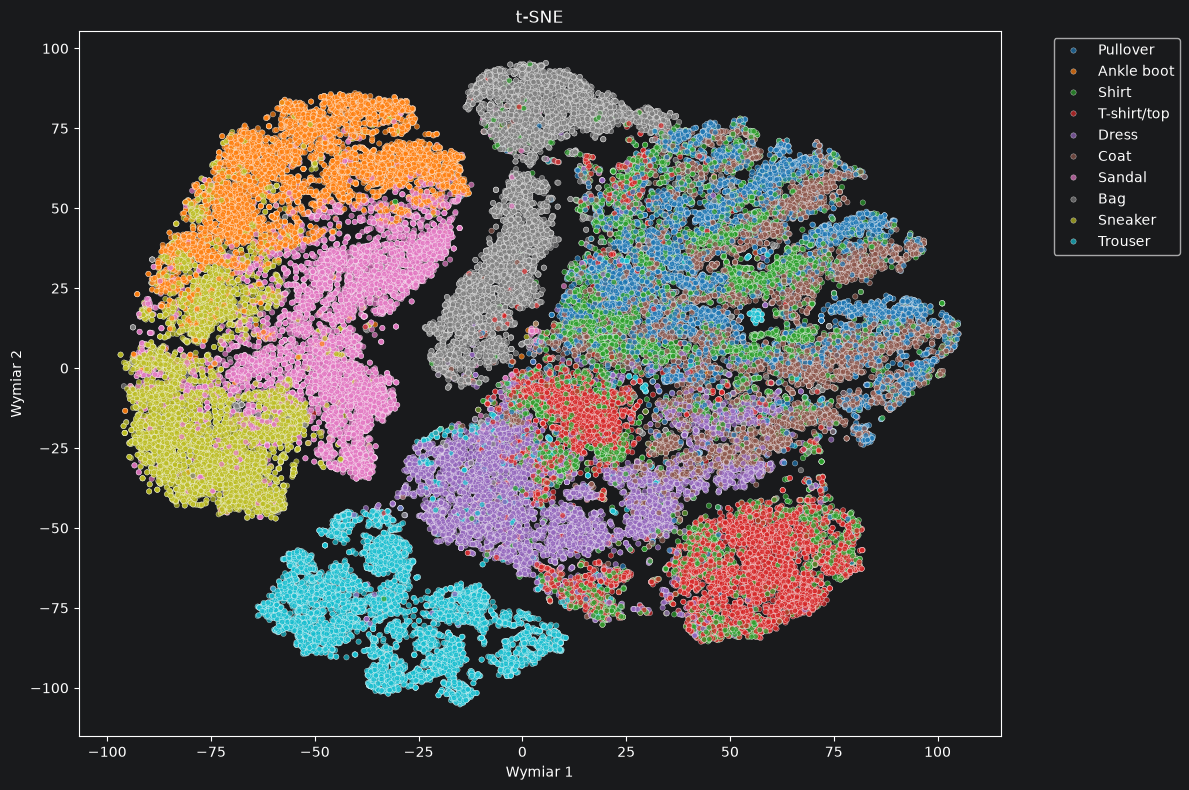

In [5]:
tsne = TSNE(n_components=2, perplexity=30.0, random_state=42)
tsne_data = tsne.fit_transform(df_pixel_only)

generate_plot(tsne_data, mapped_labels, 't-SNE')

C:\Users\jacek\DataMain\development\pwr\axion\axion-challenge\.venv\Lib\site-packages\umap\umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


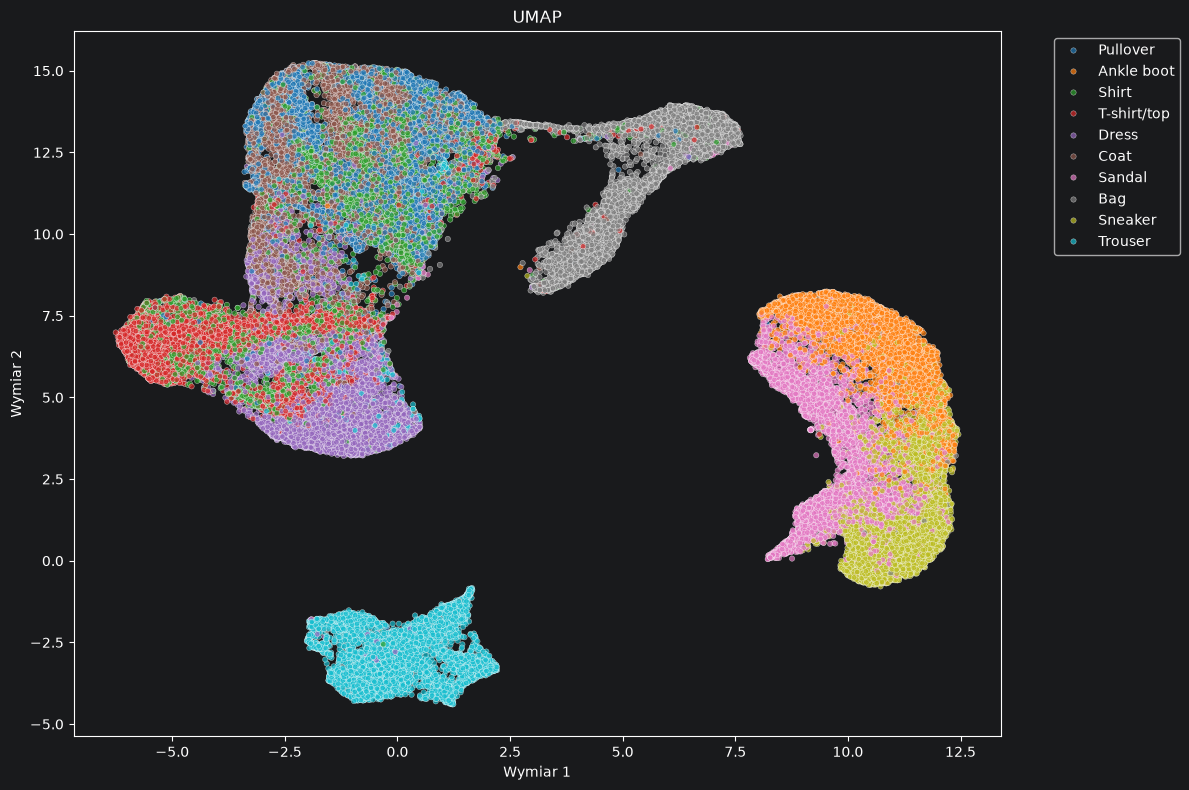

In [6]:
reducer = umap.UMAP(n_components=2, random_state=42)
umap_data = reducer.fit_transform(df_pixel_only)

generate_plot(umap_data,mapped_labels,'UMAP')


W przypadku t-SNE i UMAP sytuacja wygląda inaczej, ponieważ metody te wyznaczają już cztery konkretne grupy:

* **Grupa obuwia** (3): Sneaker, Sandal, Ankle boot
* **Grupa toreb** (1): Bag
* **Grupa spodni** (1): Trousers
* **Grupa odzieży górnej** (5): T-shirt/Top, Pullover, Dress, Shirt, Coat

Grupy toreb oraz spodni powinny stanowić najmniejszy problem dla modelu, gdyż najtrudniej pomylić je z innym rodzajem ubrań. Jeśli chodzi o grupę obuwia, pomimo że tworzy ona jedną wyspę na wykresie, widać w jej obrębie konkretne obszary, w których występują poszczególne rodzaje butów.

Inaczej sprawa się ma w przypadku grupy odzieży górnej, w której można by teoretycznie wyznaczyć dwie podgrupy:

1. **Pierwsza (mniej problematyczna):** T-shirt/Top oraz Dress
2. **Druga podgrupa:** Pullover, Shirt, Coat

Elementy tej drugiej podgrupy są silnie wymieszane ze sobą i nie widać tam żadnych konkretnych granic występowania danego typu ubrania.

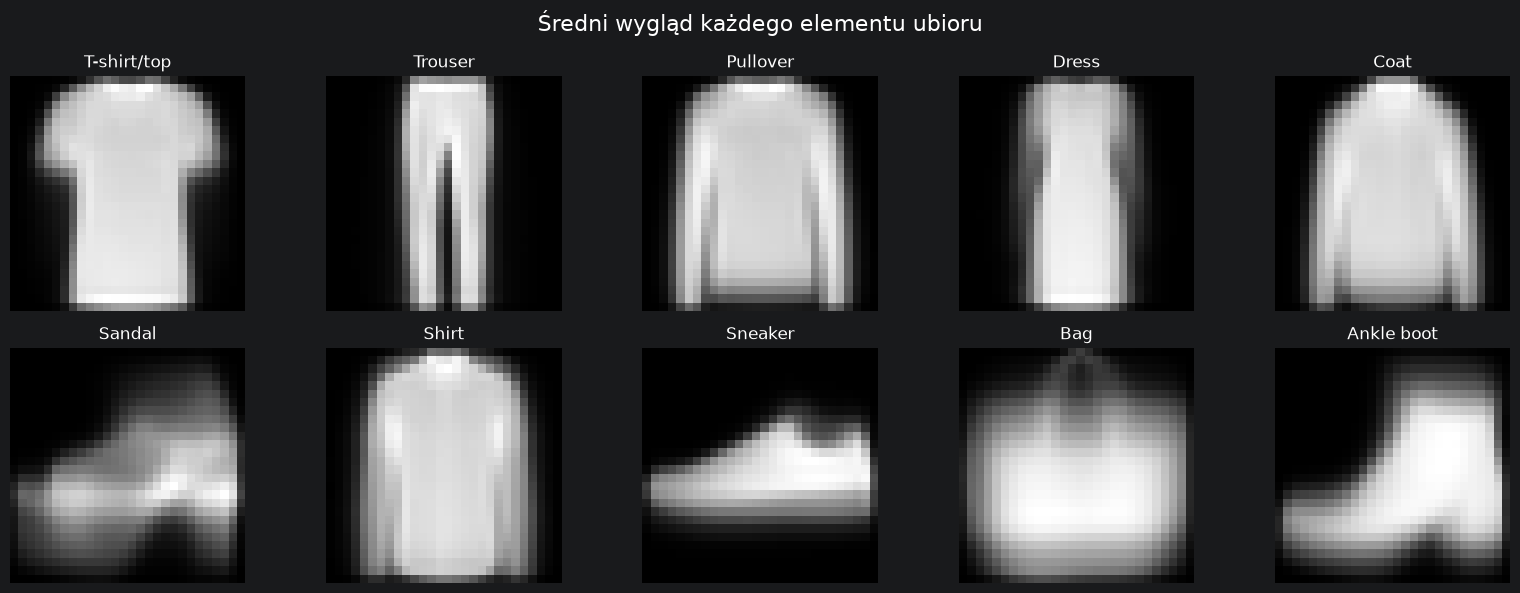

In [8]:
mean_by_class = df.groupby('label').mean()

fig, axes = plt.subplots(2, 5, figsize=(16, 6))

for label, ax in enumerate(axes.flat):
    pixels_vector = mean_by_class.loc[label].values
    pic_28x28 = pixels_vector.reshape(28, 28)


    ax.imshow(pic_28x28, cmap='gray')
    ax.set_title(clothes_dict[label])
    ax.axis('off')

plt.suptitle('Średni wygląd każdego elementu ubioru', fontsize=16)
plt.tight_layout()
plt.show()

W uśrednieniu *pullover*, *coat* i *shirt* wyglądają bardzo podobnie, dlatego model będzie miał największy problem z ich poprawnym rozpoznawaniem.

W celu weryfikacji tej hipotezy przetestuje dwa podejścia:

* **Model 1:** Trenowany na bazowym data setcie.
* **Model 2:** Trenowany na zmodyfikowanym zestawie danych, w którym *pullover*, *coat* i *shirt* zostaną scalone w jeden supertyp ubrań.

Jeśli accuracy drugiego modelu okaże się znacząco wyższe, będzie to bezpośrednim potwierdzeniem Twojej hipotezy.